# **Visión por Computadora 1 - Trabajo Práctico 2**

LUCIANA SIMON \
LUIS PAREDES \
BERNARDO EPPENSTEIN

**Objetivo:**

Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las cámaras digitales modernas. El video a procesar será: `focus_video.mov`.

1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper ["Image Sharpness Measure for Blurred Images in Frequency Domain"](./data/tp2/ImageSharpnessMeasureforBlurredImagesinFrequency.pdf) y realizar dos experimentos:
    1. Medición sobre todo el frame.
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.

Para cada experimento se debe presentar:

- Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la región de máximo enfoque.

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera automática.

> Puntos extra: Aplicar unsharp masking para expandir la zona de enfoque y devolver.

## Imports

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from typing import List, Tuple
from cv2.typing import MatLike
import ipywidgets as widgets
from IPython.display import display, clear_output

## Helpers

In [2]:
def abrir_video(ruta: str) -> cv2.VideoCapture:
    """Abre el vídeo y devuelve el objeto VideoCapture.
    Lanza FileNotFoundError si no se puede abrir."""
    cap: cv2.VideoCapture = cv2.VideoCapture(ruta)
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir el vídeo: {ruta}")
    return cap

def leer_frames(cap: cv2.VideoCapture) -> List[MatLike]:
    """Lee hasta todos los frames de cap y devuelve una lista de matrices RGB."""

    frames: List[MatLike] = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    return frames

def liberar_video(cap: cv2.VideoCapture) -> None:
    """Cierra el VideoCapture."""
    cap.release()

def calcular_espectro(img_rgb: np.ndarray) -> np.ndarray:
    """Magnitud |F| (lineal, centrada) de la imagen en escala de grises."""
    gray: MatLike = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return np.abs(np.fft.fftshift(np.fft.fft2(gray)))


############################# Plots ############################# 
def plot_frames(frames: List[float], n_frames: int) -> None:
    """Muestra n_frames frames repartidos de forma pareja a lo largo del video."""
    idxs: np.ndarray = np.linspace(0, len(frames) - 1, n_frames).astype(int)

    _fig, axes = plt.subplots(1, n_frames, figsize=(3 * n_frames, 3))

    if n_frames == 1:
        axes = [axes]

    for ax, i in zip(axes, idxs):
        ax.imshow(frames[i])
        ax.set_title(f"frame {i}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()


def plot_processed_frames(frames: List[float], title: str, ylabel: str, xlabel: str = 'Frame') -> None:
    """Muestra los frames de interes procesados por el algoritmo FM"""
    plt.figure(figsize=(10, 4))
    plt.plot(frames)

    # Marcamos el máximo con un círculo
    idx_max = int(np.argmax(frames))
    plt.plot(idx_max, frames[idx_max], 'o', markersize=9, markerfacecolor='none',
             markeredgecolor='red', markeredgewidth=2,
             label=f"Máximo enfoque: frame {idx_max} (FM = {frames[idx_max]:.3f})")
    plt.legend()

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True)
    plt.show()
    

def plot_espectros(frames: List, n_frames: int) -> None:
    """Muestra únicamente los espectros de n_frames repartidos parejas."""
    
    idxs: np.ndarray = np.linspace(0, len(frames) - 1, n_frames).astype(int)

    fig, axes = plt.subplots(1, n_frames, figsize=(3.5 * n_frames, 3.5))

    if n_frames == 1:
        axes = [axes]

    for ax, i in zip(axes, idxs):
        espectro = 20 * np.log10(calcular_espectro(frames[i]) + 1e-5)

        ax.imshow(espectro, cmap='jet')
        ax.set_title(f"Espectro frame {i}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

## Cargar frames de video

In [3]:
VIDEO_PATH = 'data/tp2/focus_video.mov'
N_FRAMES = 5

In [4]:
captura_video: cv2.VideoCapture = abrir_video(VIDEO_PATH)
frames: List[MatLike] = leer_frames(captura_video)
liberar_video(captura_video)

In [5]:
print(f"El video tiene {len(frames)} frames.")


El video tiene 171 frames.


## Visualizamos los frames y sus espectros

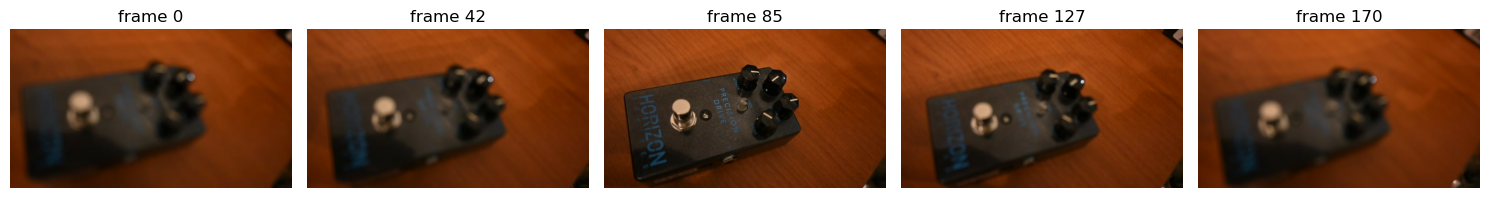

In [6]:
plot_frames(frames, N_FRAMES)

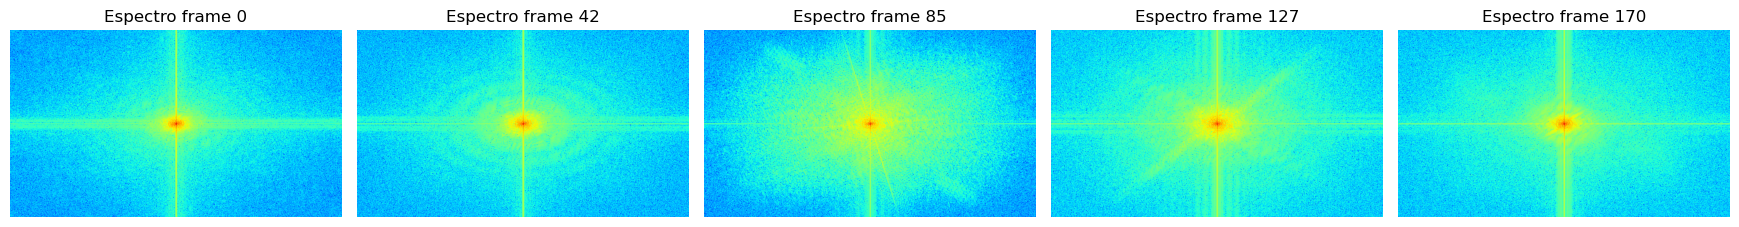

In [7]:
plot_espectros(frames, N_FRAMES)

La FFT descompone cada frame en ondas de distinta frecuencia: el centro del espectro es la frecuencia cero y, cuanto más alejado del centro, más rápido es el cambio de brillo que representa. Los bordes son cambios abruptos y requieren altas frecuencias, por lo que una imagen nítida tiene energía lejos del centro. Desenfocar equivale a promediar cada píxel con sus vecinos, lo que elimina los cambios rápidos (filtro pasa-bajos). Esto se observa en los plots: en los frames 0 y 170 el pedal está desenfocado y la mayor parte de la energía queda concentrada en el centro, mientras que en el frame 85, el más nítido, el espectro se expande hacia la periferia.

La métrica del paper cuantifica esa extensión: cuenta qué proporción de las frecuencias supera un umbral relativo al máximo, y a mayor proporción, mayor nitidez. Esperaríamos entonces encontrar un máximo cerca del frame 85 y mínimos en los extremos.

### Algoritmo que calcula métrica de Nitidez en Frecuencia (Paper)

El paper ["Image Sharpness Measure for Blurred Images in Frequency Domain" (De y Masilamani, 2013)](./data/tp2/ImageSharpnessMeasureforBlurredImagesinFrequency.pdf) propone una medida de nitidez sin referencia, llamada **FM** (*Frequency Domain Image Blur Measure*), basada en el espectro de Fourier. Su observación central es que, al aumentar el desenfoque, disminuye la cantidad de componentes de alta frecuencia.

Dada una imagen $I$ de tamaño $M \times N$, el paper propone el siguiente algoritmo:

1. Calcular la transformada de Fourier $F$ de la imagen $I$.
2. Hallar $F_c$, que se obtiene desplazando el origen de $F$ al centro.
3. Calcular la magnitud: $AF = \text{abs}(F_c)$, donde $AF$ es el valor absoluto de la transformada de Fourier centrada $F_c$ de la imagen $I$.
4. Calcular $AF_{\max} = \max(AF)$, donde $AF_{\max}$ es el valor máximo de las componentes de frecuencia de $F$. (Aclaración: es el valor que el paper denota $M$; lo renombramos para no confundirlo con el tamaño $M \times N$ de la imagen.)
5. Definir el umbral $\text{thres} = \dfrac{AF_{\max}}{1000}$ y contar los píxeles del espectro que lo superan:

$$T_H = \#\{(u,v) \;:\; AF(u,v) > \text{thres}\}$$

6. Calcular la medida de calidad de imagen (FM):

$$\text{Medida de calidad de imagen (FM)} = \frac{T_H}{M \times N} \tag{1}$$

Un valor de $FM$ mayor indica una imagen más nítida, ya que una mayor fracción de las frecuencias supera el umbral. El umbral $1/1000$ se fijó experimentalmente sobre el Berkeley Segmentation Dataset. Los autores muestran que $FM$ decrece de forma monótona al aumentar el desenfoque gaussiano o de movimiento.

In [8]:
def FM(img_rgb: np.ndarray, ratio: float = 1000) -> float:
    """Métrica FM del paper sobre una imagen o región RGB."""

    af: np.ndarray = calcular_espectro(img_rgb)        # pasos 1-3: FFT, centrado y |Fc| --> ya estaba implementado en los helpers
    af_max: float = af.max()                      # paso 4
    thres: float = af_max / ratio                 # umbral = AF_max / 1000
    t_h: int = np.count_nonzero(af > thres)     # paso 5: píxeles que superan el umbral
    m, n = af.shape
    return t_h / (m * n)                   # paso 6: FM = T_H / (M x N)

### Experimento 1: curva sobre el frame completo

Lo corremos sobre todos los frames y graficamos el resultado.

In [9]:
fm_completo: list[float] = [FM(f) for f in frames]

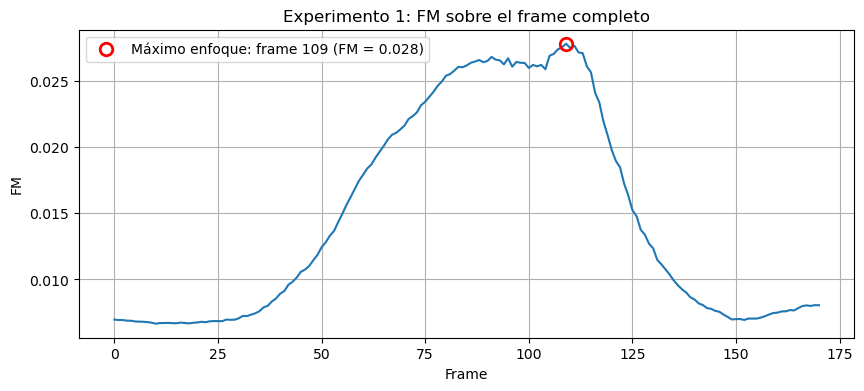

In [10]:
plot_processed_frames(fm_completo, ylabel='FM', xlabel='Frame', title='Experimento 1: FM sobre el frame completo')

Utilizando todos los frames del video, observamos que:

- El maximo enfoque esta en el frame 109.
- La curva es suave y con poco ruido. El máximo se puede ubicar sin necesidad de suavizar.
- Tenemos un contraste bajo. El frame completo incluye mucho fondo con poca alta frecuencia, que pesa en la métrica tanto en los frames enfocados como en los desenfocados.
- La zona de enfoque es ancha y poco definida. La metrica FM indica bien cuando el video está en foco en general pero distingue poco entre frames cercanos al maximo.

### Experimento 2: ROI central

Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.

In [11]:
def get_roi_coordinates(frames: List[MatLike], area: float = 0.05) -> tuple[int, int, int, int]:
    """Definimos el area de interes (ROI) centrada en el frame"""

    # Todos los frames del video tienen la misma dimension
    H, W = frames[0].shape[:2]

    print(f"La dimension del video es: {W}x{H}")

    # Mantenemos la relación de aspecto del frame: escalar cada lado por sqrt(area)
    # hace que w*h = area * W*H
    escala = np.sqrt(area)
    w, h = int(round(W * escala)), int(round(H * escala))

    print(f"Area real = {w*h/(W*H):.2%}")

    # Esquina superior izquierda para que la ROI quede centrada
    x, y = (W - w) // 2, (H - h) // 2

    print(f"ROI: {w}x{h} en (x={x}, y={y})")
    return x, y, w, h 

Corremos sobre los frames del ROI de area 5% y graficamos el resultado.

La dimension del video es: 640x360
Area real = 4.97%
ROI: 143x80 en (x=248, y=140)


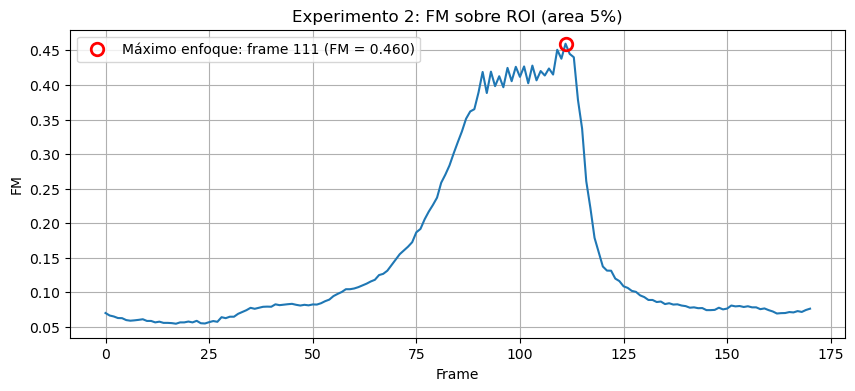

In [12]:
x, y, w, h = get_roi_coordinates(frames, area=0.05)

fm_over_roi_5_perc: list[np.float64] = [FM(f[y:y+h, x:x+w]) for f in frames]

plot_processed_frames(fm_over_roi_5_perc, 
                      ylabel='FM', 
                      xlabel='Frame', 
                      title='Experimento 2: FM sobre ROI (area 5%)'
                    )

Utilizando un ROI centrado de area 5%, observamos que:

- El maximo enfoque se encuentra en el frame 111. Se encuentra casi en el mismo frame que en el experimento anterior
- Tenemos una curva asimetrica. El FM sube de forma gradual entre los frames ≈ 50 y 90 y cae abruptamente después del frame ≈ 113. Es una buena representacion como el objeto se enfoca y desenfoca en el video.
- Tenemos un mejor contraste entre enfocado y desenfocado. Fuera de foco, la curva se mantiene en valores bajos. 
- Tenemos una zona de enfoque más angosta y definida. El area de interes (ROI 5%) discrimina mejor en qué frames el objeto está realmente nítido.
- Entre los frames 90 y 110 la curva oscila de un frame a otro. Como la ROI tiene solo 143×80 píxeles, cada coeficiente del espectro pesa más en el conteo y pequeñas variaciones entre frames se notan más. Por eso varios frames de la meseta tienen valores muy parecidos al máximo

Corremos sobre los frames del ROI de area 10% y graficamos el resultado.

La dimension del video es: 640x360
Area real = 9.99%
ROI: 202x114 en (x=219, y=123)


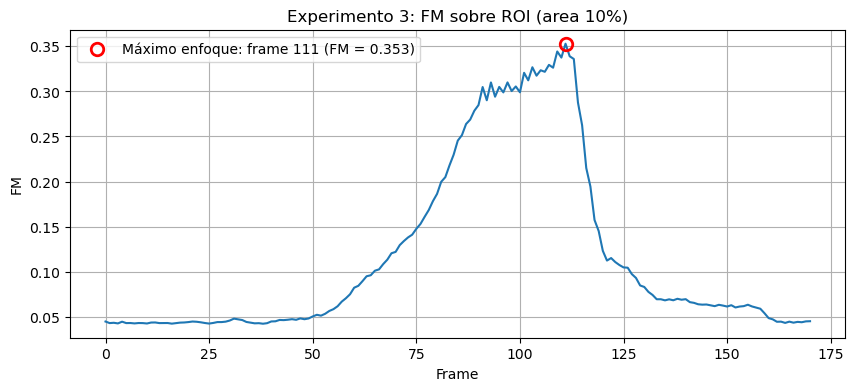

In [13]:
x, y, w, h = get_roi_coordinates(frames, area=0.10)

fm_over_roi_10_perc: list[np.float64] = [FM(f[y:y+h, x:x+w]) for f in frames]

plot_processed_frames(fm_over_roi_10_perc, 
                      ylabel='FM', 
                      xlabel='Frame', 
                      title='Experimento 3: FM sobre ROI (area 10%)'
                    )

Observamos que la forma de la curva ROI centrado de area 10% es casi identica a la del experimento anterior. El analisis del previo siguen valiendo y en particular resaltamos que el maximo enfoque cae devuelta en el frame 111.


## Conclusiones

Los valores absolutos de FM no son comparables entre experimentos porque FM se normaliza por el tamaño de la región y el umbral depende del $AF_{\max}$ de cada región. Lo que se compara entre experimentos es la forma de la curva y la posición del máximo.

Medir sobre una ROI central ha sido mejor que medir sobre el frame completo. Al ignorar el fondo, la zona de enfoque queda mejor delimitada y el pico se separa mucho mas del nivel desenfocado.

Entre las dos areas de interes (ROI 5% vs ROI 10%) ambas detectan el mismo frame de maximo enfoque y la forma de la curva de enfoque es identica. Esto tiene sentido ya que en el video vemos que el objeto se encuentra centrado.

# Puntos extra: Unsharp Masking

Aplicar unsharp masking para expandir la zona de enfoque y devolver.


## Unsharp masking

- Es un algoritmo que tiene enfocar o mejorar los bordes con un filtro de suavizado
    1. Desenfoque de la imagen con un filtro suavizador (ej. Gaussiano)
        
        $$
        f(x,y) \rightarrow f_B(x,y)
        $$
        
    2. Resta de la imagen original con la suavizada (sobreviven componentes de alta frecuencia)
        
        $$
        m(x,y) = f(x,y) - f_B(x,y)
        $$
        
    3. Agregar esa máscara a la imagen original (realce de las componentes de alta frecuencia)
        
        $$
        g(x,y) = f(x,y) + k \cdot m(x,y)
        $$
        

De manera genérica:

$$
\mathbf{g(x,y) = (k+1) \cdot f(x,y) - k \cdot f_B(x,y)}
$$

- $k = 1$: Máscara de desenfoque (unsharp masking)
- $k > 1$: Filtrado de alto impulso (highboost filtering)

### Unsharp Masking usando OpenCV

La formula generica $g = (k+1) \cdot f - k \cdot f_B$ se traduce directamente a dos metodos de OpenCV:

1. `cv2.GaussianBlur(f, (0, 0), sigma)` → $f_B$. Con `ksize=(0, 0)` OpenCV calcula el tamaño del kernel a partir de `sigma`. [Tutorial con ejemplos](https://www.tutorialkart.com/opencv/python/opencv-python-gaussian-image-smoothing/)
2. `cv2.addWeighted(f, k+1, f_B, -k, 0)` → $g$. Calcula la combinación lineal y satura el resultado a $[0, 255]$ en `uint8`, así que no hace falta hacer `np.clip` ni cambiar de tipo. [Blog con ejemplos](https://theailearner.com/tag/cv2-addweighted/)

`sigma` controla que tan "altas" son las frecuencias que se realzan (un sigma chico solo realza detalles finos) y `k` cuánto se amplifican.

In [14]:
def unsharp_masking(img: np.ndarray, k: float = 1.0, sigma: float = 2.0) -> np.ndarray:
    """Unsharp masking: g = (k+1)*f - k*f_B, con f_B = f suavizada con un filtro gaussiano.

    k = 1  -> unsharp masking clásico
    k > 1  -> highboost filtering
    """
    f_b = cv2.GaussianBlur(img, (0, 0), sigma)       # paso 1: f_B (pasa-bajos)
    return cv2.addWeighted(img, k + 1, f_b, -k, 0)   # pasos 2 y 3: f + k*(f - f_B), saturado a [0, 255]

Tomamos un frame arbitrario de la transición (algo desenfocado) y comparamos el original con su versión realzada para $k=1.0$ & $k=2.0$ y con un $\sigma = 2.0$ constante. Estudiamos sobre un ROI centrado con area 5%

In [15]:
SIGMA: float = 2.0
KS: list[float] = [1.0, 2.0]   # k = 1 (unsharp masking) y k = 2 (highboost)
FRAME_EJEMPLO: int = 80
AREA_ROI: float = 0.05

x, y, w, h = get_roi_coordinates(frames, area=AREA_ROI)
fm_over_roi: list[np.float64] = [FM(f[y:y+h, x:x+w]) for f in frames]

La dimension del video es: 640x360
Area real = 4.97%
ROI: 143x80 en (x=248, y=140)


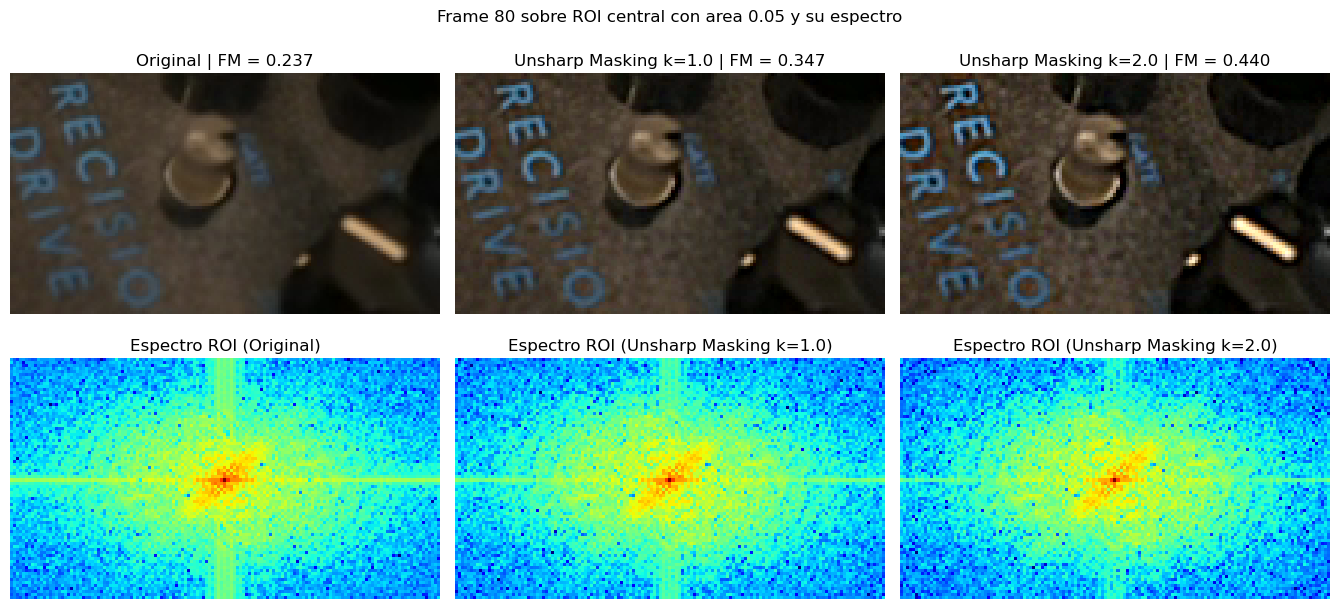

In [16]:
original: np.ndarray = frames[FRAME_EJEMPLO]
versiones: list[tuple[str, np.ndarray]] = [("Original", original)] + [(f"Unsharp Masking k={k}", unsharp_masking(original, k, SIGMA)) for k in KS]

fig, axes = plt.subplots(2, len(versiones), figsize=(4.5 * len(versiones), 6.5))

for img_index, (titulo, img_version) in enumerate(versiones):
    roi_img = img_version[y:y+h, x:x+w]

    # Imagen
    axes[0, img_index].imshow(roi_img)
    axes[0, img_index].set_title(f"{titulo} | FM = {FM(roi_img):.3f}")
    axes[0, img_index].axis('off')

    # Espectro
    axes[1, img_index].imshow(20 * np.log10(calcular_espectro(roi_img) + 1e-5), cmap='jet')
    axes[1, img_index].set_title(f"Espectro ROI ({titulo})")
    axes[1, img_index].axis('off')

fig.suptitle(f"Frame {FRAME_EJEMPLO} sobre ROI central con area {AREA_ROI} y su espectro")
plt.tight_layout()
plt.show()

Ahora aplicamos unsharp masking a todos los frames y repetimos la medición de FM sobre la misma ROI central de area de 5%

Para comparar las zonas de enfoque usamos un umbral fijo definido sobre la curva original. Un frame se considera "en foco" si su FM supera el 50% del FM maximo del video sin procesar.

Con este umbral fijo para todas las curvas, podemos ver cuántos frames adicionales pasan a estar en foco gracias al realce.

In [17]:
def zona_de_enfoque(fm: List[np.float64], umbral: float) -> np.ndarray:
    """Índices de los frames cuyo FM supera el umbral."""
    return np.flatnonzero(np.asarray(fm) >= umbral)

UMBRAL_ENFOQUE: float = 0.5 * max(fm_over_roi)

# FM sobre la ROI para cada k (el filtro se aplica al frame completo y luego se recorta)
curvas: dict[str, list[np.float64]] = {"Original": fm_over_roi}

for k in KS:
    curvas[f"Unsharp Masking k={k}"] = [FM(unsharp_masking(f, k, SIGMA)[y:y+h, x:x+w]) for f in frames]

print(f"Umbral de enfoque (fijo) = {UMBRAL_ENFOQUE:.3f}\n")

zonas: dict[str, np.ndarray] = {}
ancho: int = max(len(nombre) for nombre in curvas)   # ancho de la primera columna para alinear

for nombre, fm in curvas.items():
    zonas[nombre] = zona_de_enfoque(fm, UMBRAL_ENFOQUE)
    z: np.ndarray = zonas[nombre]
    print(f"{nombre:<{ancho}} | Maximo en frame {int(np.argmax(fm)):3d} | "
          f"Frames en foco {len(z):3d} | Rango ({z.min():3d} - {z.max():3d})")

Umbral de enfoque (fijo) = 0.230

Original              | Maximo en frame 111 | Frames en foco  37 | Rango ( 80 - 116)
Unsharp Masking k=1.0 | Maximo en frame 111 | Frames en foco  47 | Rango ( 73 - 119)
Unsharp Masking k=2.0 | Maximo en frame 111 | Frames en foco  56 | Rango ( 66 - 122)


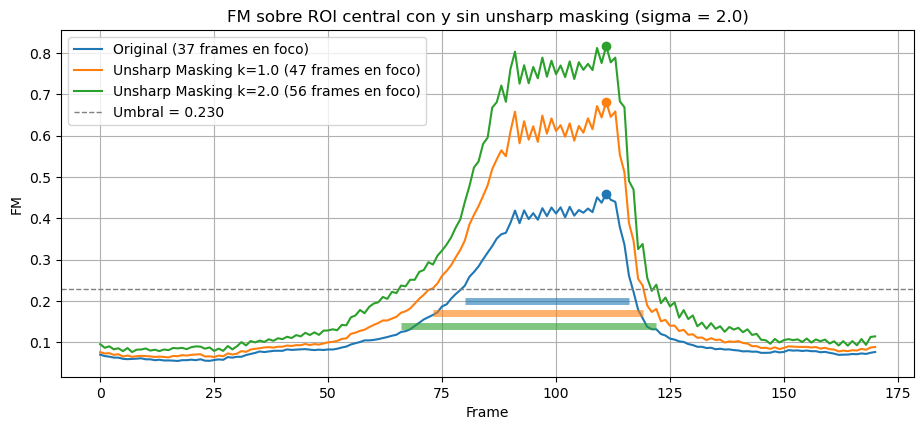

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))

for i, (nombre, fm) in enumerate(curvas.items()):
    linea, = ax.plot(fm, label=f"{nombre} ({len(zonas[nombre])} frames en foco)")
    z: np.ndarray = zonas[nombre]

    # Banda de la zona de enfoque (escalonada debajo del umbral para que no se superpongan)
    ax.hlines(UMBRAL_ENFOQUE - 0.03 * (i + 1), z.min(), z.max(), colors=linea.get_color(), linewidth=5, alpha=0.6)
    ax.plot(np.argmax(fm), max(fm), 'o', color=linea.get_color())

ax.axhline(UMBRAL_ENFOQUE, color='gray', linestyle='--', linewidth=1, label=f"Umbral = {UMBRAL_ENFOQUE:.3f}")
ax.set_xlabel('Frame')
ax.set_ylabel('FM')
ax.set_title(f'FM sobre ROI central con y sin unsharp masking (sigma = {SIGMA})')
ax.legend(loc='upper left')
ax.grid(True)
plt.show()

### Conclusión

El unsharp masking amplifica las componentes de alta frecuencia, así que mas coeficientes del espectro superan el umbral $AF_{\max}/1000$ y el FM sube en todos los frames. El efecto es mayor en los frames de transición, que todavía conservan bordes para realzar. En los frames muy desenfocados casi no queda alta frecuencia que amplificar.

Con el mismo umbral de enfoque, la zona de enfoque se expande:

| Curva | Frames en foco | Rango |
|---|---|---|
| Original | 37 | 80 – 116 |
| USM $k=1$ | 47 | 73 – 119 |
| USM $k=2$ | 56 | 66 – 122 |

Vemos que el frame de máximo enfoque no cambia (frame 111). El realce ensancha la zona de enfoque, pero no altera cuál es el frame más nítido. Sin embargo, vemos que el filtro también amplifica el ruido. Con $k$ grande el FM de los frames desenfocados también sube, y el contraste entre frames enfocados y desenfocados se reduce.